# 🏠 German Rental Price Classification: Final Evaluation
**Input:** the final Random Forest and the untouched test set, saved by `03_modeling.ipynb` (step 8.9).
**Rule:** the test set is the final exam. It is predicted **once**, and results are reported as they are (no further tuning).


## Imports
All tools used in this notebook. After a restart, run this cell first.


In [1]:
# --- Data and plots ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- Loading the saved model and test set ---
import joblib

# --- Evaluation measures ---
from sklearn.metrics import (
    accuracy_score,            # overall % correct
    balanced_accuracy_score,   # average recall of the 3 classes
    classification_report,     # precision, recall, F1 per class
    confusion_matrix,          # table of true vs predicted classes (step 9.2)
)

# Show numbers with 1 decimal instead of scientific notation
pd.set_option("display.float_format", "{:,.1f}".format)


## Load the final model and the test set


In [2]:
final_model    = joblib.load("../models/final_random_forest.joblib")   # the trained pipeline (prep + forest)
X_test, y_test = joblib.load("../models/test_set.joblib")              # the locked final exam

print("Test set:", X_test.shape)
print("Classes:", y_test.value_counts().sort_index().to_dict())


Test set: (53571, 23)
Classes: {'Low': 17873, 'Medium': 17841, 'High': 17857}


## 9.1 Final exam: overall and per-class scores
- **Accuracy:** % of test flats predicted correctly.
- **Precision:** when the model predicts a class, how often it is right (few false alarms).
- **Recall:** of the flats really in a class, how many it finds (few misses).
- **F1:** one number balancing precision and recall.
- **Balanced accuracy:** average recall of the 3 classes.


In [4]:
y_pred = final_model.predict(X_test)      # THE FINAL EXAM: predict every test flat, once

print(f"Test accuracy:          {accuracy_score(y_test, y_pred) * 100:.1f}%")
print(f"Test balanced accuracy: {balanced_accuracy_score(y_test, y_pred) * 100:.1f}%")


Test accuracy:          80.3%
Test balanced accuracy: 80.3%


In [5]:
print(classification_report(y_test, y_pred, labels=["Low", "Medium", "High"], digits=3))


              precision    recall  f1-score   support

         Low      0.853     0.831     0.842     17873
      Medium      0.709     0.715     0.712     17841
        High      0.847     0.863     0.854     17857

    accuracy                          0.803     53571
   macro avg      0.803     0.803     0.803     53571
weighted avg      0.803     0.803     0.803     53571



In [6]:
predictions = pd.DataFrame({"true": y_test, "predicted": y_pred}, index=y_test.index)
predictions.to_csv("../data/processed/test_predictions.csv")
print("Saved", len(predictions), "predictions")


Saved 53571 predictions


**Findings (9.1):**
- **Test accuracy 80.3%** (balanced accuracy 80.3%), slightly above the CV estimate (79.6% ± 0.2), as expected since the final model learned from all 214k training flats (vs ~171k per CV round). The estimate was honest; no overfitting to the validation set.
- **Easiest: High (F1 85.4%)**: its flats are distinctive (big cities, new builds, lifts, upscale interiors).
- **Hardest: Medium (F1 71.2%)**: it sits between Low and High and is the narrowest price band (€6.07–9.06), so small differences decide the class.
- **Balanced model:** precision ≈ recall for every class, and balanced accuracy = accuracy, so the model doesn't favour or avoid any class.


## 9.2 Confusion matrix
Rows = true class, columns = predicted class, each row as % of that class.
Diagonal = correct; next to it = near mistakes (acceptable); corners = **far mistakes (Low ↔ High), which must be rare** (Phase 1 criterion).


In [7]:
classes = ["Low", "Medium", "High"]

cm = confusion_matrix(y_test, y_pred, labels=classes, normalize="true") * 100   # each row as %
cm_table = pd.DataFrame(cm,
                        index=[f"true {c}" for c in classes],
                        columns=[f"pred {c}" for c in classes])
cm_table


,pred Low,pred Medium,pred High
true Low,83.1,15.9,1.0
true Medium,13.9,71.5,14.6
true High,0.4,13.3,86.3


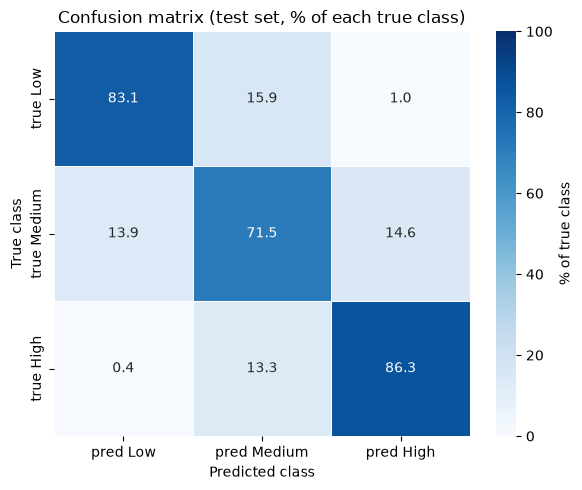

In [8]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_table, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100,
            cbar_kws={"label": "% of true class"}, linewidths=0.5, ax=ax)
ax.set_title("Confusion matrix (test set, % of each true class)")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
plt.tight_layout()
plt.savefig("../reports/figures/confusion_matrix.png", dpi=150)
plt.show()


In [9]:
far = (((y_test == "Low") & (y_pred == "High")) | ((y_test == "High") & (y_pred == "Low"))).mean() * 100
print(f"Far mistakes (Low ↔ High): {far:.2f}% of all test flats")


Far mistakes (Low ↔ High): 0.47% of all test flats
